<a href="https://colab.research.google.com/github/Rogerkamana/Assignment5rk/blob/main/Lesson_5_Assignment_Kamana_Roger.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Assignment 5 | Exploratory Data Analysis with Pandas**



**Link to Colab and GitHub**

colab: https://colab.research.google.com/drive/10j8FWbbU5yaJlrWvDVl7DaghNPYUBvg7?usp=sharing

Github:https://github.com/Rogerkamana/Assignment5rk.git

## 1. Load the Titanic dataset

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

csv_path = Path("/content/drive/MyDrive/Colab Notebooks/Titanic-Dataset.csv")
raw = pd.read_csv(csv_path)
required = {"PassengerId", "Survived", "Pclass", "Name", "Sex", "Age",
            "SibSp", "Parch", "Fare", "Cabin"}
missing_columns = required.difference(raw.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")
print(f"Loaded {raw.shape[0]:,} passenger records and {raw.shape[1]} columns.")

Mounted at /content/drive
Loaded 891 passenger records and 12 columns.


The supplied file contains 891 passenger records and 12 columns.

## 2. Inspect the data

In [3]:
print("First five rows")
display(raw.head())
print("Last five rows")
display(raw.tail())
print("Column types")
display(raw.dtypes.rename("Data type").to_frame())
print("Numeric summary")
display(raw.describe().round(2))

First five rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Last five rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


Column types


,Data type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


Numeric summary


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


Survived is coded 0 or 1, so its mean gives the overall survival rate of 38.4%. Age has 714 observed values. The median fare was 14.45, well below the mean of 32.20, consistent with a long upper tail.

## 3. Clean and preprocess the data

In [4]:
df = raw.copy()
class_order = ["First", "Second", "Third"]
class_labels = {1: "First", 2: "Second", 3: "Third"}
df["PclassCategory"] = pd.Categorical(
    df["Pclass"].map(class_labels), categories=class_order, ordered=True
)

# Use the first recorded cabin's deck letter and label blanks Unknown.
df["CabinCategory"] = (
    df["Cabin"].astype("string").str.upper().str.extract(r"^\s*([A-Z])", expand=False)
    .fillna("Unknown").astype("category")
)

# Keep track of which ages were filled so the plots can show the effect.
df["AgeImputed"] = df["Age"].isna()
mean_age = df["Age"].mean()
if pd.isna(mean_age):
    raise ValueError("At least one observed age is needed for mean imputation.")
df["Age"] = df["Age"].fillna(mean_age)

# Family counts recorded relatives aboard, excluding the passenger.
df["Family"] = df["SibSp"] + df["Parch"]
df["FamilySize"] = df["Family"] + 1

display(pd.DataFrame({"Before": raw.isna().sum(), "After": df[raw.columns].isna().sum()}))
print(f"Mean age used for imputation: {mean_age:.2f} years")
display(df["CabinCategory"].value_counts().rename("Passengers").to_frame())
display(df[["PclassCategory", "CabinCategory", "Age", "AgeImputed", "Family", "FamilySize"]].head())

,Before,After
PassengerId,0,0
Survived,0,0
Pclass,0,0
Name,0,0
Sex,0,0
Age,177,0
SibSp,0,0
Parch,0,0
Ticket,0,0
Fare,0,0


Mean age used for imputation: 29.70 years


,Passengers
CabinCategory,
Unknown,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


,PclassCategory,CabinCategory,Age,AgeImputed,Family,FamilySize
0,Third,Unknown,22.0,False,1,2
1,First,C,38.0,False,1,2
2,Third,Unknown,26.0,False,0,1
3,First,C,35.0,False,1,2
4,Third,Unknown,35.0,False,0,1


Mean imputation filled 177 ages (19.9%) at 29.70 years. The original cabin field has 687 missing entries, represented as Unknown in the derived category. The two missing embarkation entries are outside the analyses below. FamilySize includes the passenger.

## 4. Find the highest fare and largest family size

In [5]:
highest_fare_passengers = df.loc[
    df["Fare"].eq(df["Fare"].max()), ["PassengerId", "Name", "Ticket", "Fare"]
]
largest_family_passengers = df.loc[
    df["FamilySize"].eq(df["FamilySize"].max()),
    ["PassengerId", "Name", "SibSp", "Parch", "Family", "FamilySize"]
]
print(f"Highest recorded fare: {df['Fare'].max():.4f}")
display(highest_fare_passengers)
print(f"Largest family size: {df['FamilySize'].max()} including the passenger")
display(largest_family_passengers)

Highest recorded fare: 512.3292


,PassengerId,Name,Ticket,Fare
258,259,"Ward, Miss. Anna",PC 17755,512.3292
679,680,"Cardeza, Mr. Thomas Drake Martinez",PC 17755,512.3292
737,738,"Lesurer, Mr. Gustave J",PC 17755,512.3292


Largest family size: 11 including the passenger


,PassengerId,Name,SibSp,Parch,Family,FamilySize
159,160,"Sage, Master. Thomas Henry",8,2,10,11
180,181,"Sage, Miss. Constance Gladys",8,2,10,11
201,202,"Sage, Mr. Frederick",8,2,10,11
324,325,"Sage, Mr. George John Jr",8,2,10,11
792,793,"Sage, Miss. Stella Anna",8,2,10,11
846,847,"Sage, Mr. Douglas Bullen",8,2,10,11
863,864,"Sage, Miss. Dorothy Edith ""Dolly""",8,2,10,11


The tables retain ties. Three passenger rows share the maximum recorded fare of 512.3292. Seven rows have the largest family size of 11, including the passenger. These are passenger-level counts.

## 5. Practice Series and DataFrame indexing

In [6]:
names_series = df.set_index("PassengerId")["Name"]
names_ages_df = df.set_index("PassengerId")[["Name", "Age"]].copy()
names_ages_df["Age in months"] = (names_ages_df["Age"] * 12).round(1)

print("Series label lookup and position slice")
print(names_series.loc[1])
display(names_series.iloc[:3].str.upper().to_frame())
print("DataFrame label slice, including both endpoints")
display(names_ages_df.loc[1:3, ["Name", "Age in months"]])
print("DataFrame position slice")
display(names_ages_df.iloc[:3, :2])

older_passengers = names_ages_df.loc[names_ages_df["Age"].gt(50), ["Name", "Age"]]
print(f"Passengers older than 50: {len(older_passengers)}")
display(older_passengers)

Series label lookup and position slice
Braund, Mr. Owen Harris


,Name
PassengerId,
1,"BRAUND, MR. OWEN HARRIS"
2,"CUMINGS, MRS. JOHN BRADLEY (FLORENCE BRIGGS TH..."
3,"HEIKKINEN, MISS. LAINA"


DataFrame label slice, including both endpoints


,Name,Age in months
PassengerId,,
1,"Braund, Mr. Owen Harris",264.0
2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",456.0
3,"Heikkinen, Miss. Laina",312.0


DataFrame position slice


,Name,Age
PassengerId,,
1,"Braund, Mr. Owen Harris",22.0
2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
3,"Heikkinen, Miss. Laina",26.0


Passengers older than 50: 64


,Name,Age
PassengerId,,
7,"McCarthy, Mr. Timothy J",54.0
12,"Bonnell, Miss. Elizabeth",58.0
16,"Hewlett, Mrs. (Mary D Kingcome)",55.0
34,"Wheadon, Mr. Edward H",66.0
55,"Ostby, Mr. Engelhart Cornelius",65.0
...,...,...
821,"Hays, Mrs. Charles Melville (Clara Jennings Gr...",52.0
830,"Stone, Mrs. George Nelson (Martha Evelyn)",62.0
852,"Svensson, Mr. Johan",74.0


PassengerId is the index label. The label slice includes ID 3, while the positional slice stops before position 3. The ages filled at 29.70 do not enter the over-50 subset.

## 6. Create a MultiIndex survival table

In [ ]:
multi_index_df = df.groupby(["Sex", "Pclass"]).agg(
    Passengers=("Survived", "size"),
    Survivors=("Survived", "sum"),
    SurvivalRate=("Survived", "mean"),
)
display(multi_index_df.assign(SurvivalRate=multi_index_df["SurvivalRate"].map("{:.1%}".format)))
print("Female passenger groups selected from the first index level")
display(multi_index_df.xs("female", level="Sex").round(3))

Passengers  Survivors SurvivalRate
Sex    Pclass                                    
female 1               94         91        96.8%
       2               76         70        92.1%
       3              144         72        50.0%
male   1              122         45        36.9%
       2              108         17        15.7%
       3              347         47        13.5%

Female passenger groups selected from the first index level


,Passengers,Survivors,SurvivalRate
Pclass,,,
1,94,91,0.968
2,76,70,0.921
3,144,72,0.500


Each survival rate divides survivors by the number of passenger records in that sex-and-class group. For example, 91 of 94 first-class women survived (96.8%).

## 7a. Histogram of passenger ages

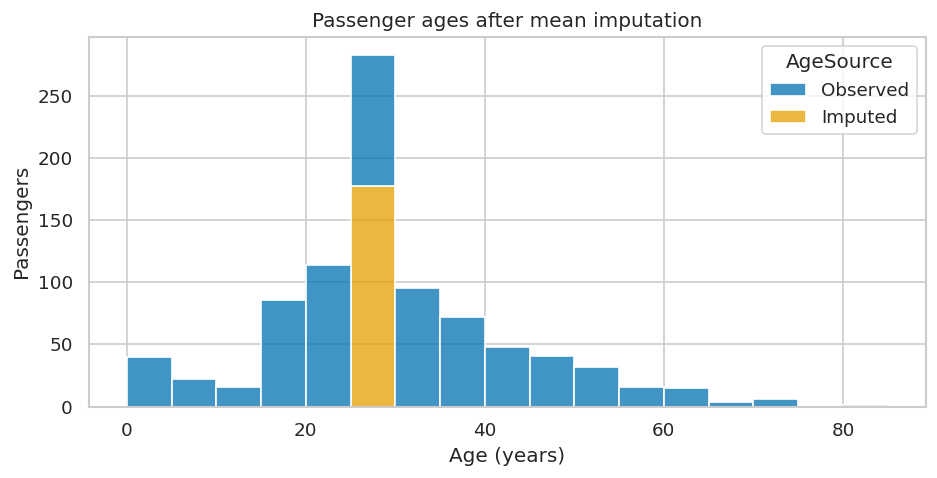

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df.assign(AgeSource=df["AgeImputed"].map(
    {False: "Observed", True: "Imputed"})), x="Age", hue="AgeSource",
    multiple="stack", binwidth=5, binrange=(0, 85),
    hue_order=["Observed", "Imputed"], palette=["#0072B2", "#E69F00"], ax=ax)
ax.set(title="Passenger ages after mean imputation", xlabel="Age (years)", ylabel="Passengers")
plt.show()

The large spike around age 30 includes all 177 imputed ages. The observed counts better describe the shape of the recorded age distribution.

## 7b. Survival rates by passenger class

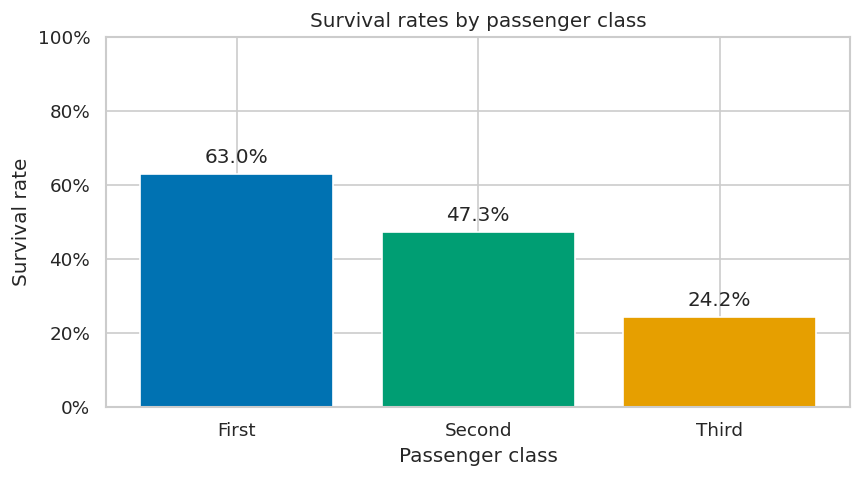

In [ ]:
class_rates = df.groupby("PclassCategory", observed=True)["Survived"].mean().reindex(class_order)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(class_rates.index, class_rates, color=["#0072B2", "#009E73", "#E69F00"])
ax.bar_label(bars, labels=[f"{rate:.1%}" for rate in class_rates], padding=4)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Survival rates by passenger class", xlabel="Passenger class",
       ylabel="Survival rate", ylim=(0, 1))
plt.show()

Survival was 63.0% in first class, 47.3% in second class and 24.2% in third class.

## 7c. Correlation heatmap

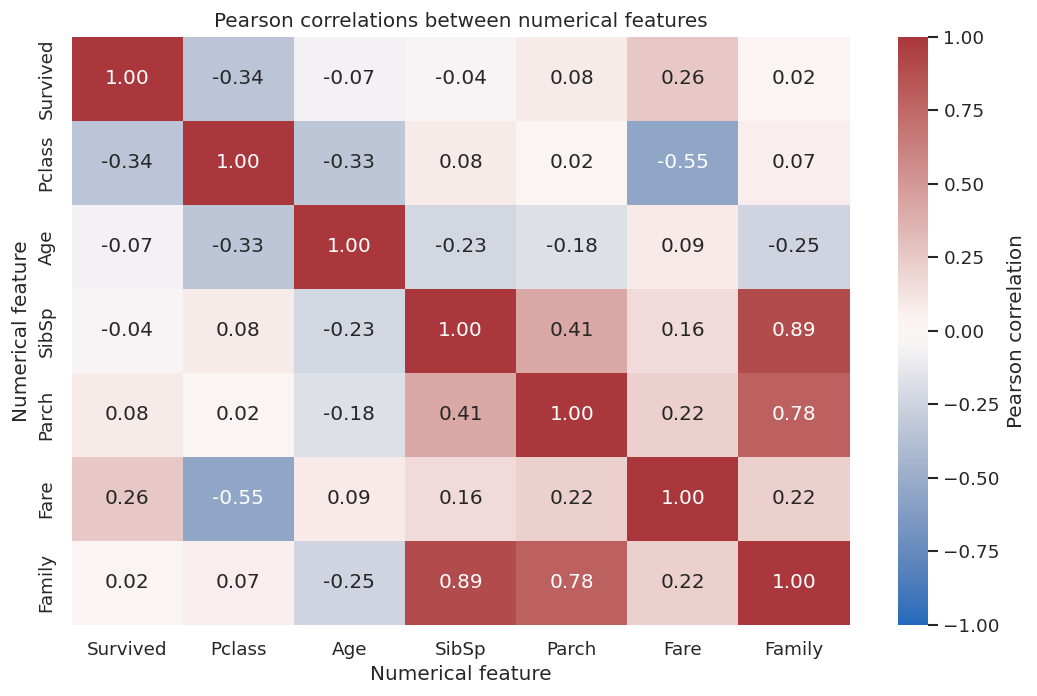

In [ ]:
numeric_features = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Family"]
correlations = df[numeric_features].corr()
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set(title="Pearson correlations between numerical features",
       xlabel="Numerical feature", ylabel="Numerical feature")
plt.tight_layout()
plt.show()

The numerical class code is negatively associated with fare and survival because larger codes represent lower classes. Family is a sum of SibSp and Parch, so its strong correlations with those components are expected. Pearson correlation summarizes linear association, and age imputation can change its magnitude.

## 7d. Pair plot of selected features

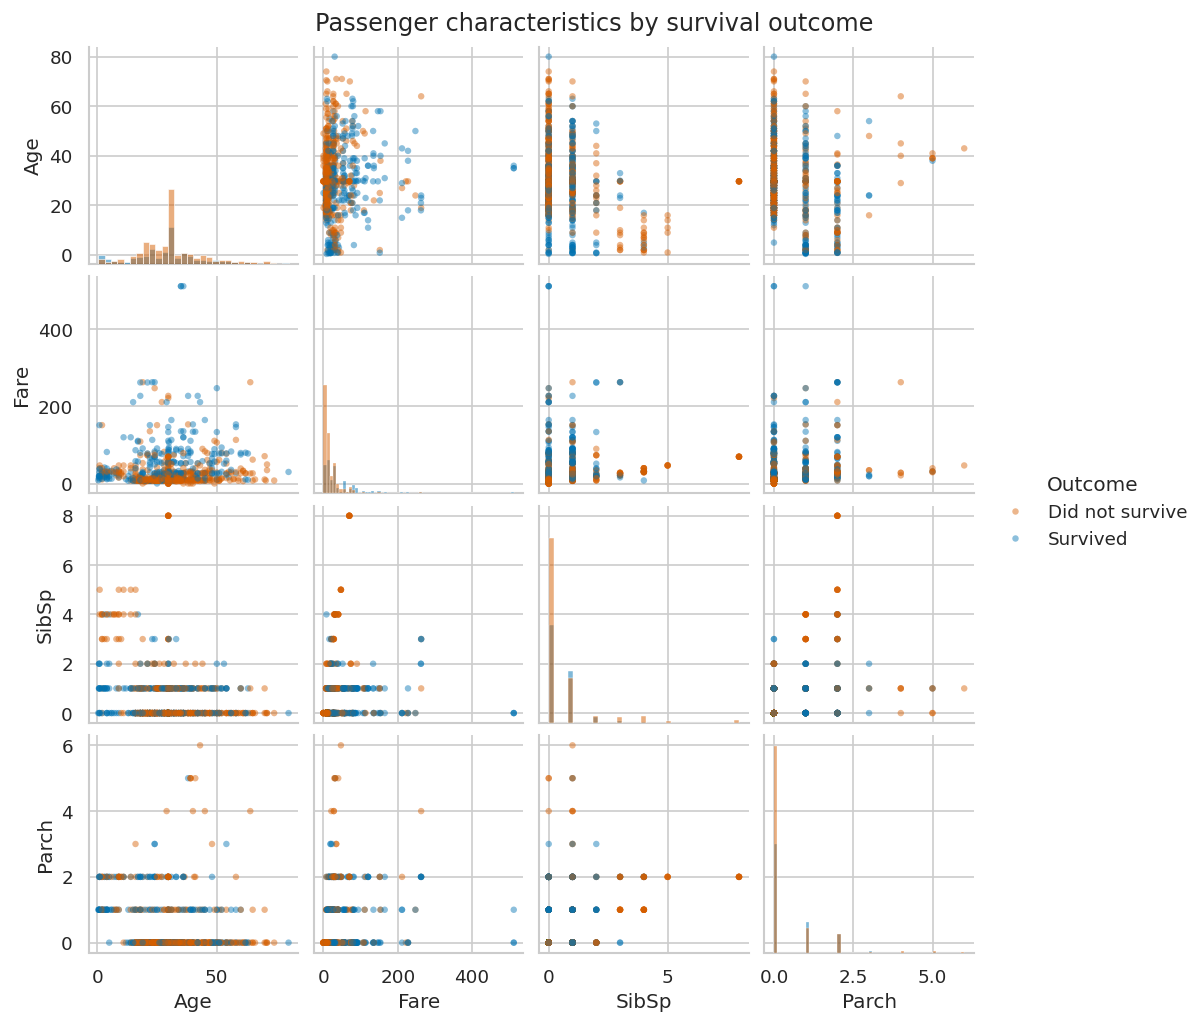

In [ ]:
outcome_labels = {0: "Did not survive", 1: "Survived"}
outcome_order = list(outcome_labels.values())
outcome_palette = {"Did not survive": "#D55E00", "Survived": "#0072B2"}
plot_data = df.assign(Outcome=df["Survived"].map(outcome_labels))
grid = sns.pairplot(plot_data, vars=["Age", "Fare", "SibSp", "Parch"], hue="Outcome",
                    hue_order=outcome_order, palette=outcome_palette, diag_kind="hist",
                    height=2.1, plot_kws={"alpha": 0.45, "s": 15, "linewidth": 0})
grid.figure.suptitle("Passenger characteristics by survival outcome", y=1.015)
plt.show()

Fare has a long right tail, and the family-count variables form bands because they are discrete. The survivor and non-survivor points overlap across these variables. The concentration near age 30 partly reflects imputation.

## 8. Compare survival by sex and passenger class

In [ ]:
survival_by_sex = df.groupby("Sex")["Survived"].agg(Passengers="size", Survivors="sum", Rate="mean")
survival_by_class = df.groupby("Pclass")["Survived"].agg(Passengers="size", Survivors="sum", Rate="mean")
display(survival_by_sex.assign(Rate=survival_by_sex["Rate"].map("{:.1%}".format)))
display(survival_by_class.assign(Rate=survival_by_class["Rate"].map("{:.1%}".format)))
survival_matrix = multi_index_df["SurvivalRate"].unstack("Sex").rename(index=class_labels)
survival_matrix["Female–male gap (pp)"] = 100 * (survival_matrix["female"] - survival_matrix["male"])
display(survival_matrix.assign(
    female=survival_matrix["female"].map("{:.1%}".format),
    male=survival_matrix["male"].map("{:.1%}".format),
).round(1))

,Passengers,Survivors,Rate
Sex,,,
female,314,233,74.2%
male,577,109,18.9%


,Passengers,Survivors,Rate
Pclass,,,
1,216,136,63.0%
2,184,87,47.3%
3,491,119,24.2%


Sex,female,male,Female–male gap (pp)
Pclass,,,
First,96.8%,36.9%,59.9
Second,92.1%,15.7%,76.4
Third,50.0%,13.5%,36.5


Overall survival was 74.2% for women and 18.9% for men. Women had higher recorded survival in all three classes. The gap was largest in second class at 76.4 percentage points. These comparisons describe associations in the supplied passenger records.

## 9. Examine age by class and sex

size  median
Pclass Sex                 
1      female    85    35.0
       male     101    40.0
2      female    74    28.0
       male      99    30.0
3      female   102    21.5
       male     253    25.0

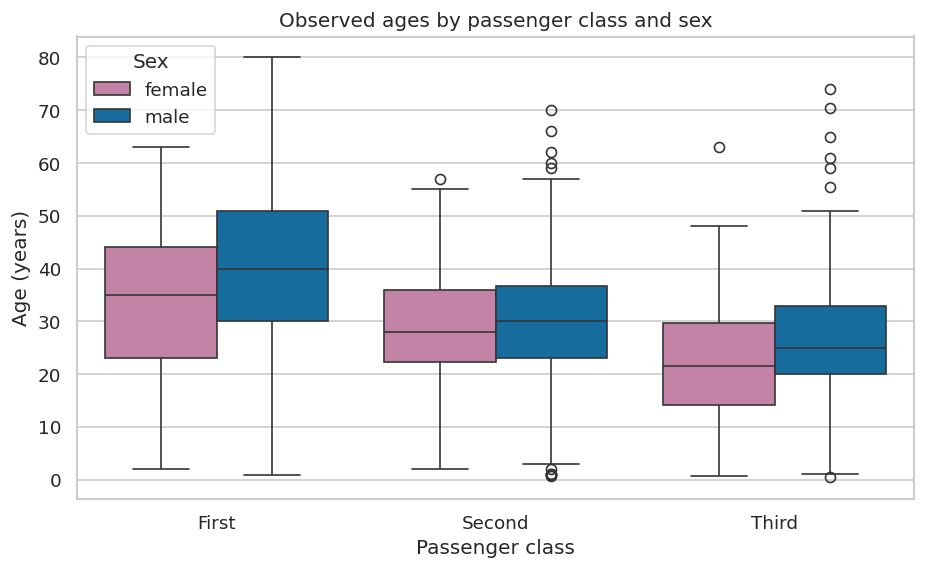

In [ ]:
# Use observed ages for distribution comparisons to avoid a spike at the mean.
observed_age = df.loc[~df["AgeImputed"]]
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=observed_age, x="PclassCategory", y="Age", hue="Sex",
            order=class_order, hue_order=["female", "male"],
            palette=["#CC79A7", "#0072B2"], ax=ax)
ax.set(title="Observed ages by passenger class and sex",
       xlabel="Passenger class", ylabel="Age (years)")
display(observed_age.groupby(["Pclass", "Sex"])["Age"].agg(["size", "median"]))
plt.show()

Median observed ages were higher in first class than in third class for both women (35 versus 21.5 years) and men (40 versus 25 years). The box plots use the 714 observed ages.

## 10. Examine fares by class and survival

size  median
Pclass Survived              
1      0           80   44.75
       1          136   77.96
2      0           97   13.00
       1           87   21.00
3      0          372    8.05
       1          119    8.52

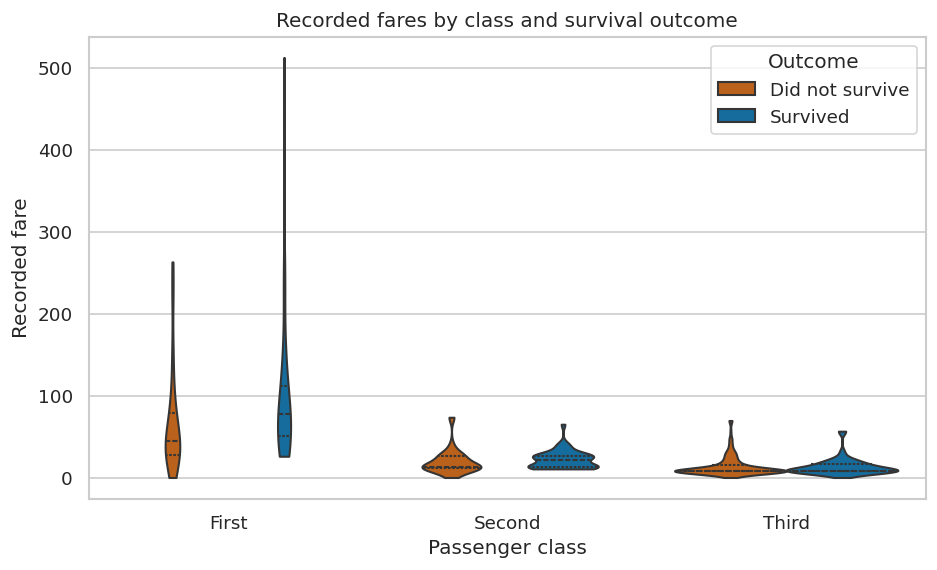

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=plot_data, x="PclassCategory", y="Fare", hue="Outcome",
               order=class_order, hue_order=outcome_order, palette=outcome_palette,
               cut=0, inner="quart", ax=ax)
ax.set(title="Recorded fares by class and survival outcome",
       xlabel="Passenger class", ylabel="Recorded fare")
display(df.groupby(["Pclass", "Survived"])["Fare"].agg(["size", "median"]).round(2))
plt.show()

Survivors had higher median recorded fares within each class. The first-class difference was largest in fare units (77.96 versus 44.75). The high-fare tail stretches the vertical scale, so the table helps compare medians in third class.

## Summary

- Survival differed strongly by passenger class and sex. Comparing both together reveals differences that the overall rates hide.
- Missing ages and cabins affect interpretation. Mean imputation preserves the age average and creates an artificial concentration near 30.
- These findings describe the supplied records. The comparisons do not establish causal effects.